<a href="https://colab.research.google.com/github/hyunwook3910/hackathon/blob/main/trash_classfication.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mostafaabla/garbage-classification")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'garbage-classification' dataset.
Path to dataset files: /kaggle/input/garbage-classification


In [ ]:
# 1. 데이터 학습 전 데이터 확인
import os, random
from collections import Counter
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

# 1) 폴더 구조 보기 (깊이 3까지)
for root, dirs, files in os.walk(path):
    depth = root[len(path):].count(os.sep)
    if depth <= 3:
        print("  " * depth + os.path.basename(root), f"(폴더 {len(dirs)}, 파일 {len(files)})")

garbage-classification (폴더 1, 파일 0)
  garbage_classification (폴더 12, 파일 0)
    metal (폴더 0, 파일 769)
    white-glass (폴더 0, 파일 775)
    biological (폴더 0, 파일 985)
    paper (폴더 0, 파일 1050)
    brown-glass (폴더 0, 파일 607)
    battery (폴더 0, 파일 945)
    trash (폴더 0, 파일 697)
    cardboard (폴더 0, 파일 891)
    shoes (폴더 0, 파일 1977)
    clothes (폴더 0, 파일 5325)
    plastic (폴더 0, 파일 865)
    green-glass (폴더 0, 파일 629)


In [ ]:
# 2) 클래스 폴더가 있는 위치 자동 탐색: 이미지 파일을 직접 가진 폴더들의 부모
IMG_EXT = (".jpg", ".jpeg", ".png")
class_dirs = {}
for root, dirs, files in os.walk(path):
    imgs = [f for f in files if f.lower().endswith(IMG_EXT)]
    if imgs:
        class_dirs[root] = imgs

data_dir = os.path.dirname(next(iter(class_dirs)))
print("data_dir:", data_dir)

# 3) 클래스별 개수 (불균형 확인)
rows = [(os.path.basename(d), len(f)) for d, f in class_dirs.items()]
df = pd.DataFrame(rows, columns=["class", "count"]).sort_values("count", ascending=False)
df["ratio(%)"] = (df["count"] / df["count"].sum() * 100).round(1)
print(df.to_string(index=False))
print("전체:", df["count"].sum(), "| 클래스 수:", len(df))

#데이터 불균형이 큼. clothes가 34.3%라 clothes라고 구분할 확률이 높다.

data_dir: /kaggle/input/garbage-classification/garbage_classification
      class  count  ratio(%)
    clothes   5325      34.3
      shoes   1977      12.7
      paper   1050       6.8
 biological    985       6.3
    battery    945       6.1
  cardboard    891       5.7
    plastic    865       5.6
white-glass    775       5.0
      metal    769       5.0
      trash    697       4.5
green-glass    629       4.1
brown-glass    607       3.9
전체: 15515 | 클래스 수: 12


In [ ]:
# 4) 이미지 크기·모드 확인 (클래스마다 30장씩 표본)
random.seed(42)
sizes, modes = [], Counter()
for d, files in class_dirs.items():
    for f in random.sample(files, min(30, len(files))):
        with Image.open(os.path.join(d, f)) as im:
            sizes.append(im.size)
            modes[im.mode] += 1

sz = pd.DataFrame(sizes, columns=["width", "height"])
print(sz.describe().round(1))
print("모드:", dict(modes))   # RGB가 아닌 것(RGBA, L 등)이 섞여 있는지 확인

#사진의 크기가 제각각이다.
#RGB 파일이 아닌 P가 있음.

       width  height
count  360.0   360.0
mean   317.0   283.1
std    124.3   111.3
min    132.0   115.0
25%    225.0   200.0
50%    259.0   225.0
75%    400.0   384.0
max    865.0   711.0
모드: {'RGB': 359, 'P': 1}


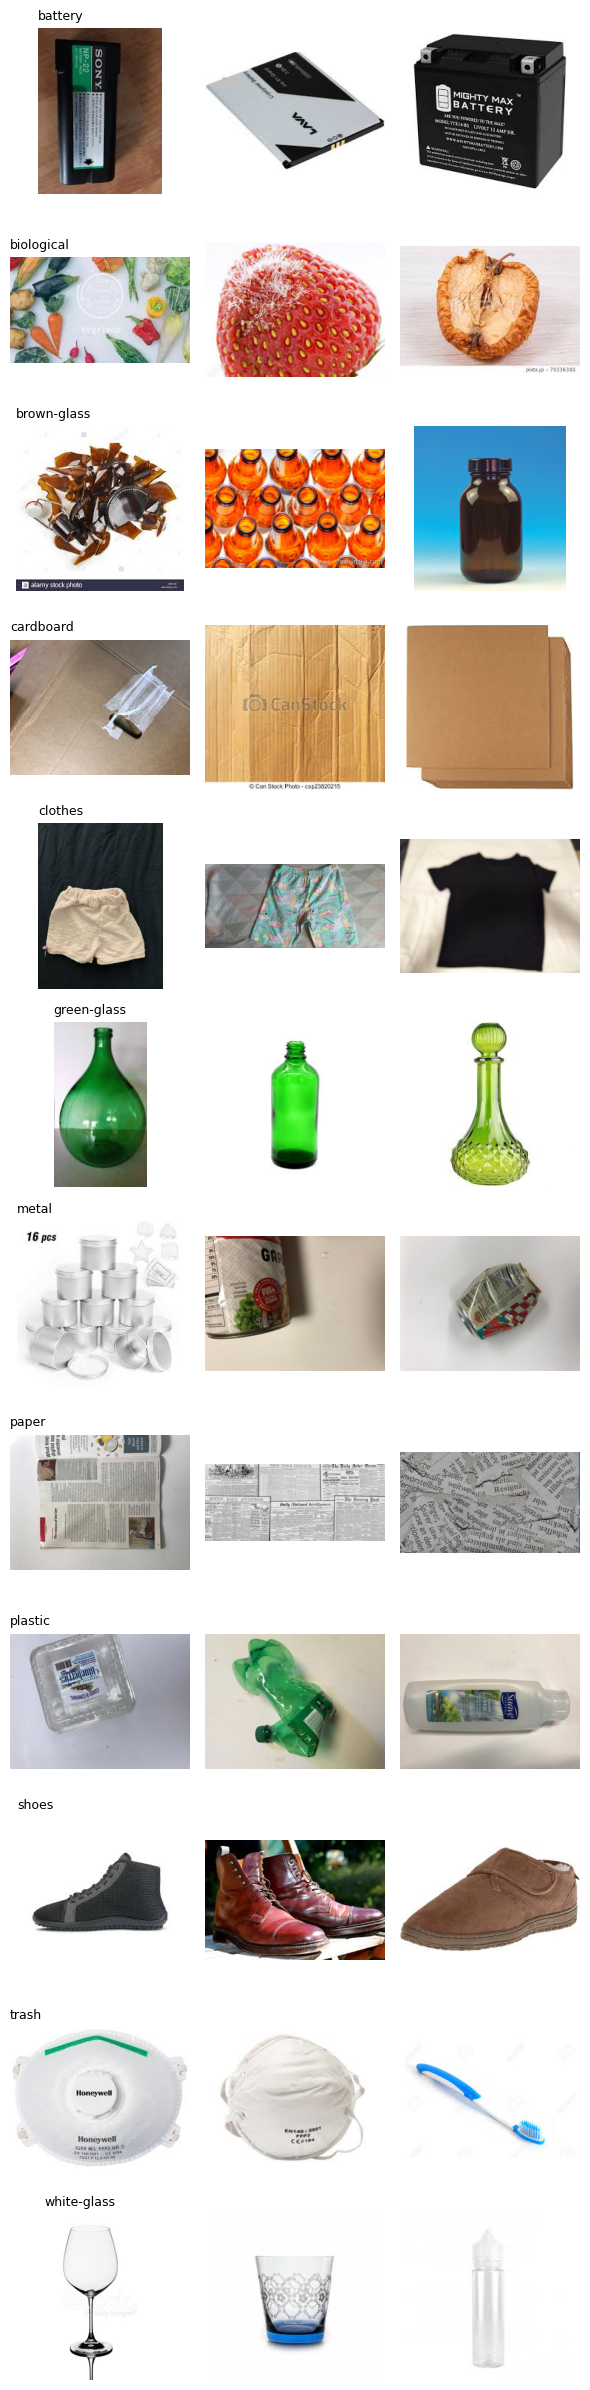

In [ ]:
# 5) 클래스별 샘플 이미지 (클래스당 3장)
names = sorted(class_dirs, key=lambda d: os.path.basename(d))
fig, axes = plt.subplots(len(names), 3, figsize=(6, 2 * len(names)))
for i, d in enumerate(names):
    for j, f in enumerate(random.sample(class_dirs[d], 3)):
        axes[i, j].imshow(Image.open(os.path.join(d, f)).convert("RGB"))
        axes[i, j].axis("off")
        if j == 0:
            axes[i, j].set_title(os.path.basename(d), fontsize=9, loc="left")
plt.tight_layout()
plt.show()

In [ ]:
import os, random
import numpy as np
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

data_dir = "/kaggle/input/garbage-classification/garbage_classification"
classes = sorted(os.listdir(data_dir))
class_to_idx = {c: i for i, c in enumerate(classes)}

paths, labels = [], []
for c in classes:
    for f in sorted(os.listdir(os.path.join(data_dir, c))):
        if f.lower().endswith((".jpg", ".jpeg", ".png")):
            paths.append(os.path.join(data_dir, c, f))
            labels.append(class_to_idx[c])
labels = np.array(labels)
print(len(paths), classes)

# 클래스별로 섞은 뒤 같은 비율로 자른다 (3주차: 섞고 나누기)
rng = np.random.default_rng(SEED)
train_idx, val_idx, test_idx = [], [], []
for k in range(len(classes)):
    idx = np.where(labels == k)[0]
    rng.shuffle(idx)
    n_tr, n_va = int(len(idx) * 0.70), int(len(idx) * 0.15)
    train_idx += idx[:n_tr].tolist()
    val_idx   += idx[n_tr:n_tr + n_va].tolist()
    test_idx  += idx[n_tr + n_va:].tolist()

print("train/val/test:", len(train_idx), len(val_idx), len(test_idx))

15515 ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']
train/val/test: 10854 2321 2340


In [ ]:
IMG = 128

def load_img(p):
    with Image.open(p) as im:
        im = im.convert("RGB").resize((IMG, IMG), Image.BILINEAR)
        return np.asarray(im, dtype=np.uint8)          # (128, 128, 3)

X = np.stack([load_img(p) for p in paths])             # (N, 128, 128, 3)
X = torch.from_numpy(X).permute(0, 3, 1, 2).contiguous()  # (N, 3, 128, 128): PyTorch는 채널이 앞
y = torch.from_numpy(labels).long()                    # CrossEntropyLoss는 정수 클래스 번호(Long)

print(X.shape, X.dtype, y.shape, y.dtype)

# 다시 쓰려고 저장 (Kaggle이면 /kaggle/working, Colab이면 /content)
torch.save({"X": X, "y": y, "classes": classes,
            "train_idx": train_idx, "val_idx": val_idx, "test_idx": test_idx},
           "garbage_128.pt")

torch.Size([15515, 3, 128, 128]) torch.uint8 torch.Size([15515]) torch.int64


In [ ]:
def channel_stats(X, idx, chunk=512):
    s = torch.zeros(3); s2 = torch.zeros(3); n = 0
    for i in range(0, len(idx), chunk):
        b = X[idx[i:i + chunk]].float() / 255.0         # (b, 3, H, W)
        s  += b.sum(dim=(0, 2, 3))
        s2 += (b ** 2).sum(dim=(0, 2, 3))
        n  += b.shape[0] * b.shape[2] * b.shape[3]
    mean = s / n
    std = (s2 / n - mean ** 2).sqrt()
    return mean, std

mean, std = channel_stats(X, train_idx)
print("mean:", mean, "std:", std)

mean: tensor([0.6581, 0.6157, 0.5851]) std: tensor([0.2765, 0.2878, 0.3016])


In [ ]:
class GarbageDataset(Dataset):
    def __init__(self, X, y, indices, mean, std):
        self.X, self.y = X, y
        self.indices = indices
        self.mean = mean.view(3, 1, 1)
        self.std = std.view(3, 1, 1)

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        j = self.indices[i]
        x = self.X[j].float() / 255.0                   # 0~1
        x = (x - self.mean) / self.std                  # 학습 기준 표준화
        return x, self.y[j]

train_set = GarbageDataset(X, y, train_idx, mean, std)
val_set   = GarbageDataset(X, y, val_idx,   mean, std)
test_set  = GarbageDataset(X, y, test_idx,  mean, std)

train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
val_loader   = DataLoader(val_set,   batch_size=64, shuffle=False)
test_loader  = DataLoader(test_set,  batch_size=64, shuffle=False)
print(len(train_loader), len(val_loader), len(test_loader))   # batch 개수

170 37 37


In [ ]:
bx, by = next(iter(train_loader))
print("batch shape:", tuple(bx.shape), bx.dtype)      # (64, 3, 128, 128) float32
print("label:", by.shape, by.dtype)                   # (64,) int64
print("min/max:", bx.min().item(), bx.max().item())
print("nan:", torch.isnan(bx).sum().item())           # 0이어야 함

# 분할마다 클래스 비율이 비슷한지
import pandas as pd
rows = {name: np.bincount(labels[idx], minlength=len(classes))
        for name, idx in [("train", train_idx), ("val", val_idx), ("test", test_idx)]}
print(pd.DataFrame(rows, index=classes))

batch shape: (64, 3, 128, 128) torch.float32
label: torch.Size([64]) torch.int64
min/max: -2.3804163932800293 1.3753865957260132
nan: 0
             train  val  test
battery        661  141   143
biological     689  147   149
brown-glass    424   91    92
cardboard      623  133   135
clothes       3727  798   800
green-glass    440   94    95
metal          538  115   116
paper          735  157   158
plastic        605  129   131
shoes         1383  296   298
trash          487  104   106
white-glass    542  116   117


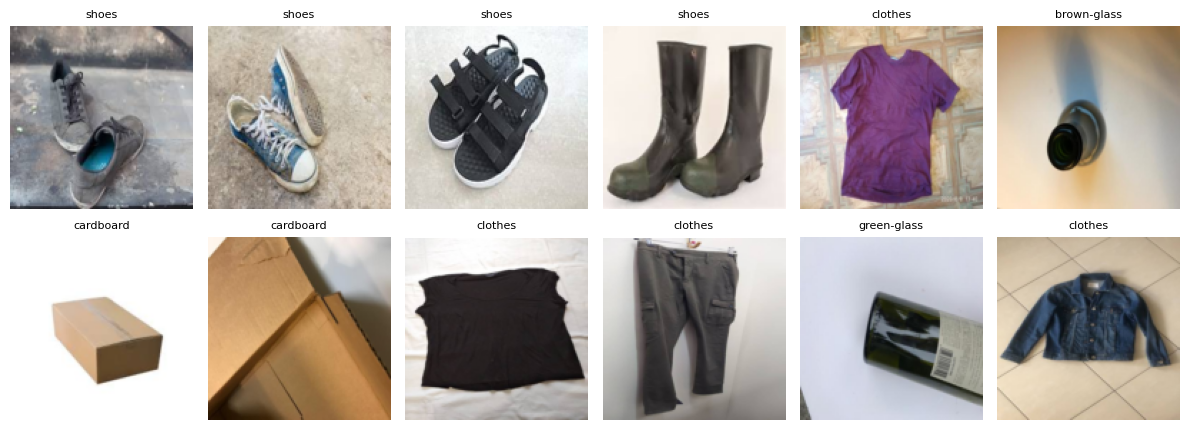

In [ ]:
# 표준화를 되돌려 눈으로 확인 (정상적으로 읽혔는지)
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))
for ax, img, lab in zip(axes.flat, bx[:12], by[:12]):
    ax.imshow((img * std.view(3,1,1) + mean.view(3,1,1)).clamp(0, 1).permute(1, 2, 0))
    ax.set_title(classes[lab], fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

In [ ]:
import time, copy
import torch, torch.nn as nn
import matplotlib.pyplot as plt

SEED = 42
torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

N_CLASSES = len(classes)   # 12

class BaseCNN(nn.Module):
    def __init__(self, n_classes=12, in_size=128):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1),   nn.ReLU(), nn.MaxPool2d(2),   # 128 → 64
            nn.Conv2d(16, 32, 3, padding=1),  nn.ReLU(), nn.MaxPool2d(2),   # 64 → 32
            nn.Conv2d(32, 64, 3, padding=1),  nn.ReLU(), nn.MaxPool2d(2),   # 32 → 16
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 16 → 8
        )
        with torch.no_grad():                       # 8주차: 더미 입력으로 Flatten 크기 알아내기
            flat = self.features(torch.zeros(1, 3, in_size, in_size)).numel()
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(flat, 128), nn.ReLU(),
            nn.Linear(128, n_classes),              # softmax는 넣지 않는다 (CrossEntropyLoss가 처리)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model = BaseCNN(N_CLASSES).to(device)

# 단계별 shape 추적: 학습 전에 반드시 확인
x = torch.zeros(1, 3, 128, 128, device=device)
with torch.no_grad():
    for layer in list(model.features) + list(model.classifier):
        x = layer(x)
        print(f"{layer.__class__.__name__:10s} {tuple(x.shape)}")

n_params = sum(p.numel() for p in model.parameters())
print("파라미터 수:", n_params)   # 1,147,692가 나와야 정상

device: cuda
Conv2d     (1, 16, 128, 128)
ReLU       (1, 16, 128, 128)
MaxPool2d  (1, 16, 64, 64)
Conv2d     (1, 32, 64, 64)
ReLU       (1, 32, 64, 64)
MaxPool2d  (1, 32, 32, 32)
Conv2d     (1, 64, 32, 32)
ReLU       (1, 64, 32, 32)
MaxPool2d  (1, 64, 16, 16)
Conv2d     (1, 128, 16, 16)
ReLU       (1, 128, 16, 16)
MaxPool2d  (1, 128, 8, 8)
Flatten    (1, 8192)
Linear     (1, 128)
ReLU       (1, 128)
Linear     (1, 12)
파라미터 수: 1147692


In [ ]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
EPOCHS = 15

def run_epoch(loader, train):
    model.train(train)                               # train / eval 전환
    total_loss, correct, n = 0.0, 0, 0
    cm = torch.zeros(N_CLASSES * N_CLASSES, dtype=torch.long)
    with torch.enable_grad() if train else torch.no_grad():
        for bx, by in loader:
            bx, by = bx.to(device), by.to(device)
            out = model(bx)                          # 1) 예측
            loss = loss_fn(out, by)                  # 2) 손실
            if train:
                optimizer.zero_grad()                # 3) 기울기 초기화
                loss.backward()                      # 4) 역전파
                optimizer.step()                     # 5) 파라미터 수정
            pred = out.argmax(dim=1)
            total_loss += loss.item() * len(by)
            correct += (pred == by).sum().item()
            n += len(by)
            cm += torch.bincount((by * N_CLASSES + pred).cpu(), minlength=N_CLASSES ** 2)
    cm = cm.view(N_CLASSES, N_CLASSES).float()
    bal_acc = (cm.diag() / cm.sum(dim=1)).mean().item()   # 클래스별 recall의 평균
    return total_loss / n, correct / n, bal_acc

hist = {k: [] for k in ["tr_loss", "tr_acc", "va_loss", "va_acc", "va_bal"]}
best_val, best_state = float("inf"), None
t0 = time.time()
for ep in range(1, EPOCHS + 1):
    tr_loss, tr_acc, _        = run_epoch(train_loader, train=True)
    va_loss, va_acc, va_bal   = run_epoch(val_loader,   train=False)
    for k, v in zip(hist, [tr_loss, tr_acc, va_loss, va_acc, va_bal]):
        hist[k].append(v)
    if va_loss < best_val:                           # 검증 손실이 가장 낮은 시점을 저장
        best_val, best_epoch = va_loss, ep
        best_state = copy.deepcopy(model.state_dict())
    print(f"ep {ep:2d} | train loss {tr_loss:.4f} acc {tr_acc:.3f} | "
          f"val loss {va_loss:.4f} acc {va_acc:.3f} bal {va_bal:.3f} | {time.time()-t0:.0f}s")

torch.save(best_state, "base_cnn_best.pt")
print("best epoch:", best_epoch, "| val loss:", round(best_val, 4))

ep  1 | train loss 1.5013 acc 0.513 | val loss 1.0932 acc 0.638 bal 0.525 | 6s
ep  2 | train loss 0.9436 acc 0.693 | val loss 0.8775 acc 0.721 bal 0.636 | 11s
ep  3 | train loss 0.7459 acc 0.754 | val loss 0.8002 acc 0.739 bal 0.664 | 16s
ep  4 | train loss 0.6052 acc 0.798 | val loss 0.8242 acc 0.740 bal 0.648 | 22s
ep  5 | train loss 0.4948 acc 0.835 | val loss 0.7926 acc 0.754 bal 0.662 | 27s
ep  6 | train loss 0.3952 acc 0.866 | val loss 0.8055 acc 0.767 bal 0.691 | 33s
ep  7 | train loss 0.2876 acc 0.905 | val loss 0.8366 acc 0.776 bal 0.698 | 38s
ep  8 | train loss 0.2121 acc 0.927 | val loss 0.9299 acc 0.774 bal 0.709 | 43s
ep  9 | train loss 0.1504 acc 0.949 | val loss 1.0389 acc 0.770 bal 0.697 | 48s
ep 10 | train loss 0.1075 acc 0.964 | val loss 1.4323 acc 0.748 bal 0.648 | 54s
ep 11 | train loss 0.1116 acc 0.963 | val loss 1.1514 acc 0.757 bal 0.685 | 59s
ep 12 | train loss 0.0891 acc 0.971 | val loss 1.3737 acc 0.744 bal 0.672 | 65s
ep 13 | train loss 0.0750 acc 0.975 | val

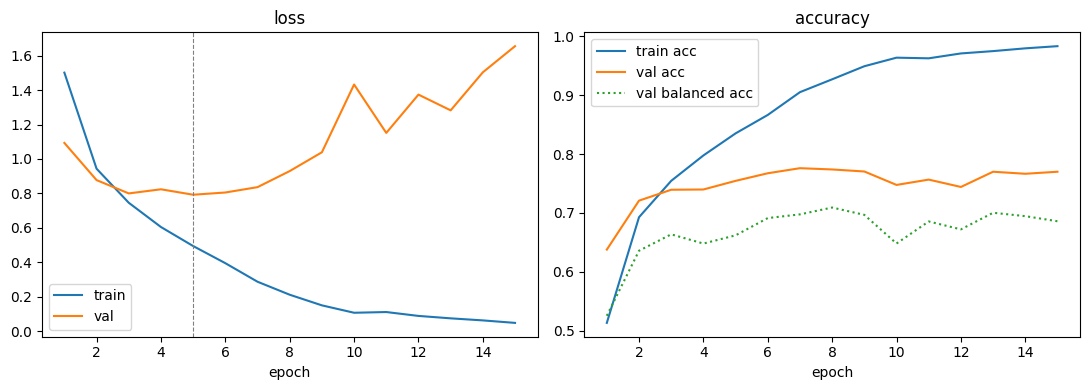

학습-검증 정확도 차이(마지막): 0.213


In [ ]:
ep_axis = range(1, EPOCHS + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ep_axis, hist["tr_loss"], label="train"); ax[0].plot(ep_axis, hist["va_loss"], label="val")
ax[0].axvline(best_epoch, color="gray", ls="--", lw=0.8); ax[0].set_title("loss"); ax[0].legend()
ax[1].plot(ep_axis, hist["tr_acc"], label="train acc"); ax[1].plot(ep_axis, hist["va_acc"], label="val acc")
ax[1].plot(ep_axis, hist["va_bal"], label="val balanced acc", ls=":")
ax[1].set_title("accuracy"); ax[1].legend()
for a in ax: a.set_xlabel("epoch")
plt.tight_layout(); plt.show()
print("학습-검증 정확도 차이(마지막):", round(hist["tr_acc"][-1] - hist["va_acc"][-1], 3))

In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

model.load_state_dict(torch.load("base_cnn_best.pt", map_location=device))
model.eval()

all_pred, all_true, all_conf = [], [], []
with torch.no_grad():
    for bx, by in val_loader:                    # shuffle=False → 순서 = val_idx 순서
        prob = torch.softmax(model(bx.to(device)), dim=1)
        conf, pred = prob.max(dim=1)
        all_pred.append(pred.cpu()); all_true.append(by); all_conf.append(conf.cpu())
pred, true, conf = torch.cat(all_pred), torch.cat(all_true), torch.cat(all_conf)
print("val acc:", round((pred == true).float().mean().item(), 4))

K = len(classes)
cm = torch.bincount(true * K + pred, minlength=K * K).view(K, K).numpy()   # 행=정답, 열=예측

support = cm.sum(1)
recall = np.diag(cm) / support
precision = np.diag(cm) / np.maximum(cm.sum(0), 1)
f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-9)
df = pd.DataFrame({"support": support, "recall": recall.round(3),
                   "precision": precision.round(3), "f1": f1.round(3)},
                  index=classes).sort_values("recall")
print(df)
print("balanced acc:", round(recall.mean(), 4), "| macro-F1:", round(f1.mean(), 4))

val acc: 0.7544
             support  recall  precision     f1
metal            115   0.426      0.590  0.495
white-glass      116   0.509      0.663  0.576
brown-glass       91   0.538      0.653  0.590
biological       147   0.578      0.780  0.664
paper            157   0.586      0.829  0.687
plastic          129   0.643      0.441  0.524
trash            104   0.654      0.708  0.680
shoes            296   0.696      0.780  0.736
cardboard        133   0.714      0.714  0.714
battery          141   0.752      0.752  0.752
green-glass       94   0.872      0.882  0.877
clothes          798   0.974      0.827  0.895
balanced acc: 0.6619 | macro-F1: 0.6824


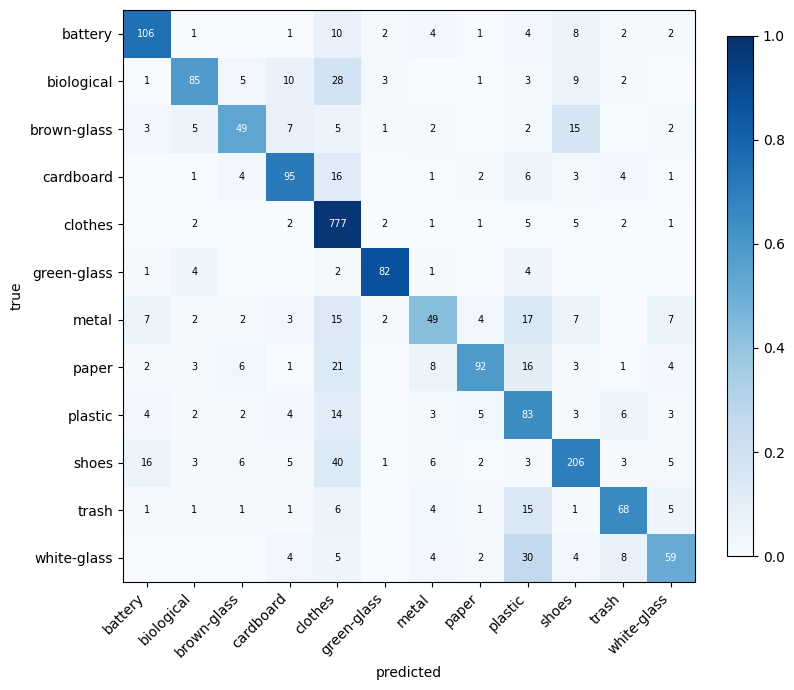

shoes        → clothes       40장 (13.5%)
white-glass  → plastic       30장 (25.9%)
biological   → clothes       28장 (19.0%)
paper        → clothes       21장 (13.4%)
metal        → plastic       17장 (14.8%)
shoes        → battery       16장 (5.4%)
paper        → plastic       16장 (10.2%)
cardboard    → clothes       16장 (12.0%)
trash        → plastic       15장 (14.4%)
metal        → clothes       15장 (13.0%)


In [ ]:
cmn = cm / cm.sum(1, keepdims=True)              # 행 기준 비율
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(K)); ax.set_xticklabels(classes, rotation=45, ha="right")
ax.set_yticks(range(K)); ax.set_yticklabels(classes)
for i in range(K):
    for j in range(K):
        if cm[i, j] > 0:
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                    color="white" if cmn[i, j] > 0.5 else "black")
ax.set_xlabel("predicted"); ax.set_ylabel("true"); plt.colorbar(im, fraction=0.04)
plt.tight_layout(); plt.show()

pairs = [(cm[i, j], i, j) for i in range(K) for j in range(K) if i != j and cm[i, j] > 0]
for n, i, j in sorted(pairs, reverse=True)[:10]:
    print(f"{classes[i]:12s} → {classes[j]:12s} {n:3d}장 ({n / support[i] * 100:.1f}%)")

오답: 570 / 2321
평균 확신도 | 정답일 때: 0.89 | 오답일 때: 0.628


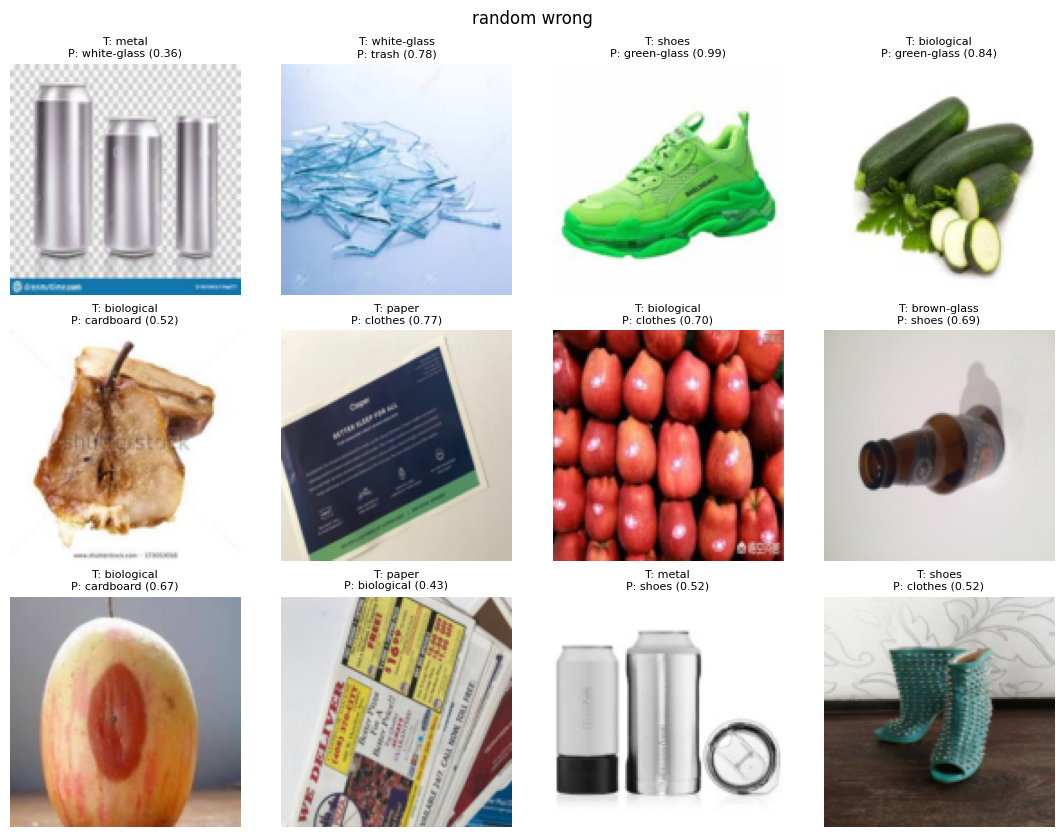

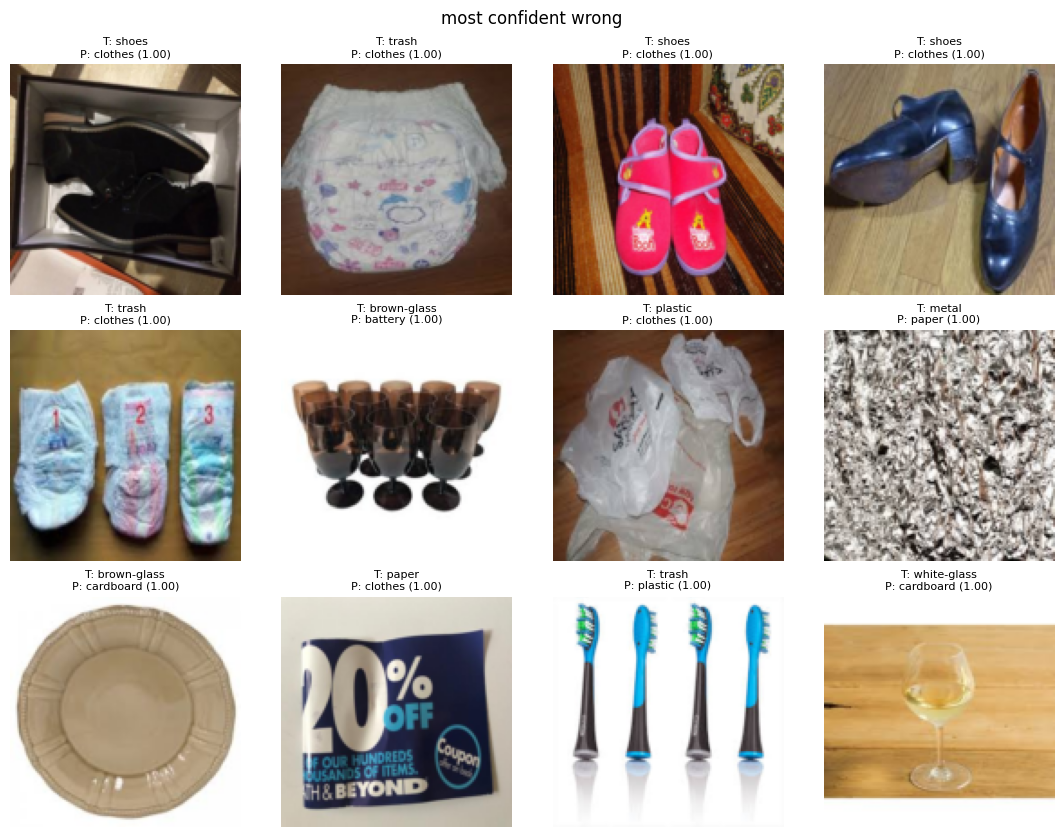

In [ ]:
wrong = (pred != true).nonzero().flatten()
print("오답:", len(wrong), "/", len(true))
print("평균 확신도 | 정답일 때:", round(conf[pred == true].mean().item(), 3),
      "| 오답일 때:", round(conf[wrong].mean().item(), 3))

def show(idx_list, title):
    fig, axes = plt.subplots(3, 4, figsize=(11, 8.5))
    for ax, i in zip(axes.flat, idx_list):
        img = X[val_idx[i]].permute(1, 2, 0)           # uint8 원본 (표준화 전)
        ax.imshow(img)
        ax.set_title(f"T: {classes[true[i]]}\nP: {classes[pred[i]]} ({conf[i]:.2f})", fontsize=8)
        ax.axis("off")
    fig.suptitle(title); plt.tight_layout(); plt.show()

g = torch.Generator().manual_seed(0)
show(wrong[torch.randperm(len(wrong), generator=g)[:12]].tolist(), "random wrong")
order = conf[wrong].argsort(descending=True)
show(wrong[order[:12]].tolist(), "most confident wrong")

In [ ]:
import math, time, copy
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader

EPOCHS, BATCH, LR, SEED = 20, 64, 1e-3, 42
K = len(classes); N_CLASSES = K
device = "cuda" if torch.cuda.is_available() else "cpu"

# ---------- 모델 (옵션으로 BatchNorm / Dropout 켜기) ----------
class CNN(nn.Module):
    def __init__(self, n_classes=12, in_size=128, bn=False, dropout=0.0):
        super().__init__()
        chans, layers = [3, 16, 32, 64, 128], []
        for cin, cout in zip(chans[:-1], chans[1:]):
            layers.append(nn.Conv2d(cin, cout, 3, padding=1))
            if bn: layers.append(nn.BatchNorm2d(cout))          # Conv 다음, ReLU 앞
            layers += [nn.ReLU(), nn.MaxPool2d(2)]
        self.features = nn.Sequential(*layers)
        flat = chans[-1] * (in_size // 2 ** 4) ** 2              # 128*8*8 = 8192 (더미 통과 없이 계산)
        head = [nn.Flatten()]
        if dropout: head.append(nn.Dropout(dropout))
        head += [nn.Linear(flat, 128), nn.ReLU()]
        if dropout: head.append(nn.Dropout(dropout))
        head.append(nn.Linear(128, n_classes))                   # softmax 없음
        self.classifier = nn.Sequential(*head)

    def forward(self, x):
        return self.classifier(self.features(x))

# ---------- 증강 (torch로 직접 구현, 학습 배치에만 적용) ----------
def augment(x, max_rot=15, scale=(0.9, 1.1), shift=0.1):
    B, dev = x.size(0), x.device
    ang = (torch.rand(B, device=dev) * 2 - 1) * max_rot * math.pi / 180
    sc = torch.empty(B, device=dev).uniform_(*scale)
    flip = (torch.rand(B, device=dev) < 0.5).float() * 2 - 1      # +1 또는 -1 (좌우 반전)
    tx = (torch.rand(B, device=dev) * 2 - 1) * shift * 2          # 격자 좌표는 [-1, 1] 범위
    ty = (torch.rand(B, device=dev) * 2 - 1) * shift * 2
    cos, sin = torch.cos(ang) / sc, torch.sin(ang) / sc
    theta = torch.zeros(B, 2, 3, device=dev)
    theta[:, 0, 0], theta[:, 0, 1], theta[:, 0, 2] = cos * flip, -sin, tx
    theta[:, 1, 0], theta[:, 1, 1], theta[:, 1, 2] = sin * flip, cos, ty
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    return F.grid_sample(x, grid, padding_mode="reflection", align_corners=False)

# ---------- 한 epoch ----------
eval_loss_fn = nn.CrossEntropyLoss()                              # 평가 손실은 항상 가중치 없이 (비교 가능하게)

def run_epoch(model, loader, train, optimizer=None, loss_fn=None, aug=False):
    model.train(train)
    tot, correct, n = 0.0, 0, 0
    cm = torch.zeros(K * K, dtype=torch.long)
    with torch.set_grad_enabled(train):
        for bx, by in loader:
            bx, by = bx.to(device), by.to(device)
            if train and aug:
                bx = augment(bx)
            out = model(bx)
            loss = (loss_fn if train else eval_loss_fn)(out, by)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            pred = out.argmax(dim=1)
            tot += loss.item() * len(by); correct += (pred == by).sum().item(); n += len(by)
            cm += torch.bincount((by * K + pred).cpu(), minlength=K * K)
    cm = cm.view(K, K).float()
    return tot / n, correct / n, (cm.diag() / cm.sum(1)).mean().item()

# ---------- 실험 한 번 ----------
train_eval_loader = DataLoader(train_set, batch_size=256, shuffle=False)   # 학습 정확도를 깨끗하게(증강/드롭아웃 없이) 재기용

def run_experiment(name, bn=False, dropout=0.0, aug=False, class_weight=False):
    torch.manual_seed(SEED); np.random.seed(SEED)                 # 실험마다 새 모델 + 같은 시드
    model = CNN(N_CLASSES, bn=bn, dropout=dropout).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    if class_weight:
        cnt = torch.bincount(y[train_idx], minlength=K).float()
        loss_fn = nn.CrossEntropyLoss(weight=(cnt.sum() / (K * cnt)).to(device))
    else:
        loss_fn = nn.CrossEntropyLoss()
    tr_loader = DataLoader(train_set, batch_size=BATCH, shuffle=True,
                           generator=torch.Generator().manual_seed(SEED))

    h = {k: [] for k in ["va_loss", "va_acc", "va_bal", "tr_acc"]}
    best_loss, best_bal = float("inf"), -1
    t0 = time.time()
    for ep in range(1, EPOCHS + 1):
        run_epoch(model, tr_loader, True, optimizer, loss_fn, aug)
        _, tr_acc, _ = run_epoch(model, train_eval_loader, False)
        va_loss, va_acc, va_bal = run_epoch(model, val_loader, False)
        for k, v in zip(h, [va_loss, va_acc, va_bal, tr_acc]):
            h[k].append(v)
        if va_loss < best_loss:
            best_loss, state_loss = va_loss, copy.deepcopy(model.state_dict())
        if va_bal > best_bal:
            best_bal, state_bal = va_bal, copy.deepcopy(model.state_dict())
    torch.save(state_loss, f"{name}_best_loss.pt"); torch.save(state_bal, f"{name}_best_bal.pt")
    print(f"[{name}] 완료 {time.time()-t0:.0f}s | 파라미터 {sum(p.numel() for p in model.parameters()):,}")
    return dict(hist=h, time=time.time() - t0, params=sum(p.numel() for p in model.parameters()))

configs = {
    "base":        dict(),
    "dropout":     dict(dropout=0.5),
    "batchnorm":   dict(bn=True),
    "augment":     dict(aug=True),
    "all3":        dict(dropout=0.5, bn=True, aug=True),
    "all3+weight": dict(dropout=0.5, bn=True, aug=True, class_weight=True),
}
results = {n: run_experiment(n, **c) for n, c in configs.items()}

[base] 완료 187s | 파라미터 1,147,692
[dropout] 완료 176s | 파라미터 1,147,692
[batchnorm] 완료 210s | 파라미터 1,148,172
[augment] 완료 221s | 파라미터 1,147,692
[all3] 완료 246s | 파라미터 1,148,172
[all3+weight] 완료 247s | 파라미터 1,148,172


      model  params  time_s  best_loss_ep  va_loss  va_acc  va_bal   gap  max_bal  max_bal_ep
       base 1147692     187             4    0.747   0.757   0.680 0.095    0.706          20
    dropout 1147692     176            11    0.681   0.794   0.719 0.104    0.737          20
  batchnorm 1148172     210             7    0.706   0.783   0.721 0.096    0.742          14
    augment 1147692     221            10    0.656   0.790   0.720 0.078    0.743          20
       all3 1148172     246            20    0.783   0.748   0.646 0.033    0.652          18
all3+weight 1148172     247            17    0.880   0.719   0.673 0.026    0.686          18


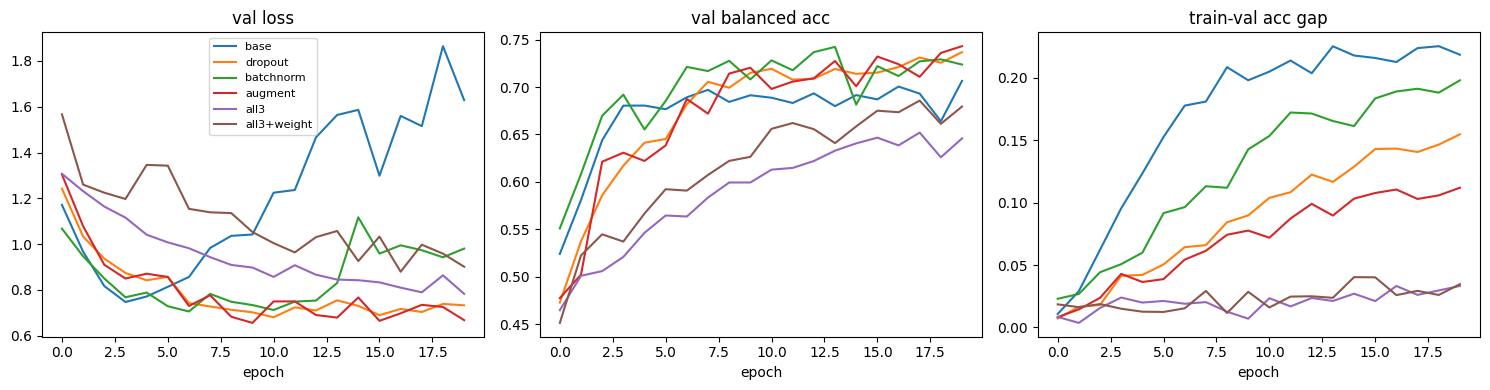

In [ ]:
rows = []
for n, r in results.items():
    h = r["hist"]; b = int(np.argmin(h["va_loss"])); m = int(np.argmax(h["va_bal"]))
    rows.append(dict(model=n, params=r["params"], time_s=round(r["time"]),
                     best_loss_ep=b + 1, va_loss=round(h["va_loss"][b], 3),
                     va_acc=round(h["va_acc"][b], 3), va_bal=round(h["va_bal"][b], 3),
                     gap=round(h["tr_acc"][b] - h["va_acc"][b], 3),
                     max_bal=round(h["va_bal"][m], 3), max_bal_ep=m + 1))
print(pd.DataFrame(rows).to_string(index=False))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for n, r in results.items():
    ax[0].plot(r["hist"]["va_loss"], label=n)
    ax[1].plot(r["hist"]["va_bal"], label=n)
    ax[2].plot(np.array(r["hist"]["tr_acc"]) - np.array(r["hist"]["va_acc"]), label=n)
for a, t in zip(ax, ["val loss", "val balanced acc", "train-val acc gap"]):
    a.set_title(t); a.set_xlabel("epoch")
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

In [ ]:
def run_experiment(name, bn=False, dropout=0.0, aug=False, class_weight=False,
                   epochs=60, patience=10):
    torch.manual_seed(SEED); np.random.seed(SEED)
    model = CNN(N_CLASSES, bn=bn, dropout=dropout).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    if class_weight:
        cnt = torch.bincount(y[train_idx], minlength=K).float()
        loss_fn = nn.CrossEntropyLoss(weight=(cnt.sum() / (K * cnt)).to(device))
    else:
        loss_fn = nn.CrossEntropyLoss()
    tr_loader = DataLoader(train_set, batch_size=BATCH, shuffle=True,
                           generator=torch.Generator().manual_seed(SEED))

    h = {k: [] for k in ["va_loss", "va_acc", "va_bal", "tr_acc"]}
    best_loss, best_bal, since_best = float("inf"), -1, 0
    t0 = time.time()
    for ep in range(1, epochs + 1):
        run_epoch(model, tr_loader, True, optimizer, loss_fn, aug)
        _, tr_acc, _ = run_epoch(model, train_eval_loader, False)
        va_loss, va_acc, va_bal = run_epoch(model, val_loader, False)
        for k, v in zip(h, [va_loss, va_acc, va_bal, tr_acc]):
            h[k].append(v)
        if va_bal > best_bal:
            best_bal, state_bal = va_bal, copy.deepcopy(model.state_dict())
        if va_loss < best_loss:
            best_loss, state_loss, since_best = va_loss, copy.deepcopy(model.state_dict()), 0
        else:
            since_best += 1
            if since_best >= patience:               # 조기 종료
                print(f"[{name}] epoch {ep}에서 조기 종료 (최저 손실 epoch {ep - patience})")
                break
    torch.save(state_loss, f"{name}_best_loss.pt"); torch.save(state_bal, f"{name}_best_bal.pt")
    n_par = sum(p.numel() for p in model.parameters())
    print(f"[{name}] 완료 {time.time()-t0:.0f}s | {len(h['va_loss'])} epoch | 파라미터 {n_par:,}")
    return dict(hist=h, time=time.time() - t0, params=n_par)

configs2 = {
    "augment_es":     dict(aug=True),
    "bn+aug_es":      dict(bn=True, aug=True),
    "all3_es":        dict(dropout=0.5, bn=True, aug=True),
    "all3+weight_es": dict(dropout=0.5, bn=True, aug=True, class_weight=True),
}
results2 = {n: run_experiment(n, **c) for n, c in configs2.items()}

rows = []
for n, r in results2.items():
    h = r["hist"]; b = int(np.argmin(h["va_loss"]))
    rows.append(dict(model=n, epochs_run=len(h["va_loss"]), best_loss_ep=b + 1,
                     time_s=round(r["time"]), va_loss=round(h["va_loss"][b], 3),
                     va_acc=round(h["va_acc"][b], 3), va_bal=round(h["va_bal"][b], 3),
                     gap=round(h["tr_acc"][b] - h["va_acc"][b], 3)))
print(pd.DataFrame(rows).to_string(index=False))

[augment_es] epoch 30에서 조기 종료 (최저 손실 epoch 20)
[augment_es] 완료 315s | 30 epoch | 파라미터 1,147,692
[bn+aug_es] epoch 34에서 조기 종료 (최저 손실 epoch 24)
[bn+aug_es] 완료 398s | 34 epoch | 파라미터 1,148,172
[all3_es] 완료 722s | 60 epoch | 파라미터 1,148,172
[all3+weight_es] 완료 722s | 60 epoch | 파라미터 1,148,172
         model  epochs_run  best_loss_ep  time_s  va_loss  va_acc  va_bal   gap
    augment_es          30            20     315    0.658   0.815   0.754 0.119
     bn+aug_es          34            24     398    0.597   0.831   0.782 0.083
       all3_es          60            55     722    0.548   0.828   0.764 0.065
all3+weight_es          60            58     722    0.633   0.805   0.768 0.070


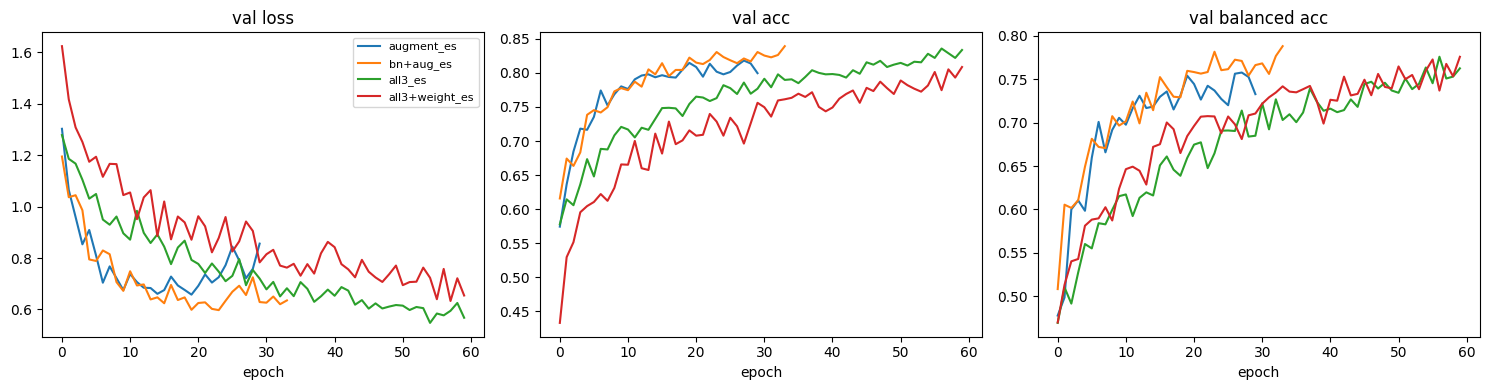

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for n, r in results2.items():
    h = r["hist"]
    ax[0].plot(h["va_loss"], label=n); ax[1].plot(h["va_acc"], label=n); ax[2].plot(h["va_bal"], label=n)
for a, t in zip(ax, ["val loss", "val acc", "val balanced acc"]):
    a.set_title(t); a.set_xlabel("epoch")
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

In [ ]:
def run_experiment_cos(name, bn=False, dropout=0.0, aug=False, epochs=60):
    torch.manual_seed(SEED); np.random.seed(SEED)
    model = CNN(N_CLASSES, bn=bn, dropout=dropout).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    loss_fn = nn.CrossEntropyLoss()
    tr_loader = DataLoader(train_set, batch_size=BATCH, shuffle=True,
                           generator=torch.Generator().manual_seed(SEED))
    h = {k: [] for k in ["va_loss", "va_acc", "va_bal", "tr_acc"]}
    t0 = time.time()
    for ep in range(1, epochs + 1):
        run_epoch(model, tr_loader, True, optimizer, loss_fn, aug)
        scheduler.step()
        _, tr_acc, _ = run_epoch(model, train_eval_loader, False)
        va_loss, va_acc, va_bal = run_epoch(model, val_loader, False)
        for k, v in zip(h, [va_loss, va_acc, va_bal, tr_acc]):
            h[k].append(v)
    torch.save(model.state_dict(), f"{name}_final.pt")       # 마지막 epoch 가중치를 그대로 저장
    print(f"[{name}] 완료 {time.time()-t0:.0f}s")
    return dict(hist=h, time=time.time() - t0)

cfg3 = {"bn+aug_cos": dict(bn=True, aug=True),
        "all3_cos":   dict(bn=True, aug=True, dropout=0.5)}
results3 = {n: run_experiment_cos(n, **c) for n, c in cfg3.items()}

rows = []
for n, r in results3.items():
    h = r["hist"]
    rows.append(dict(model=n,
                     final_loss=round(h["va_loss"][-1], 3), final_acc=round(h["va_acc"][-1], 3),
                     final_bal=round(h["va_bal"][-1], 3),
                     last5_acc=round(np.mean(h["va_acc"][-5:]), 3),     # 마지막 5 epoch 평균 (노이즈 완화)
                     last5_bal=round(np.mean(h["va_bal"][-5:]), 3),
                     gap=round(h["tr_acc"][-1] - h["va_acc"][-1], 3), time_s=round(r["time"])))
print(pd.DataFrame(rows).to_string(index=False))

[bn+aug_cos] 완료 747s
[all3_cos] 완료 743s
     model  final_loss  final_acc  final_bal  last5_acc  last5_bal   gap  time_s
bn+aug_cos       0.507      0.861      0.813      0.860      0.811 0.124     747
  all3_cos       0.619      0.807      0.731      0.807      0.733 0.065     743


In [ ]:
def predict(model, loader):
    model.eval(); P, T, C = [], [], []
    with torch.no_grad():
        for bx, by in loader:
            conf, p = torch.softmax(model(bx.to(device)), 1).max(1)
            P.append(p.cpu()); T.append(by); C.append(conf.cpu())
    return torch.cat(P), torch.cat(T), torch.cat(C)

def metrics(P, T):
    cm = torch.bincount(T * K + P, minlength=K * K).view(K, K).numpy()
    sup = cm.sum(1); rec = np.diag(cm) / sup
    prec = np.diag(cm) / np.maximum(cm.sum(0), 1)
    f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-9)
    return cm, rec, prec, f1, (P == T).float().mean().item()

final = CNN(N_CLASSES, bn=True).to(device)
final.load_state_dict(torch.load("bn+aug_cos_final.pt", map_location=device))
base = CNN(N_CLASSES).to(device)
base.load_state_dict(torch.load("base_best_loss.pt", map_location=device))

out = {}
for name, m in [("base(참고)", base), ("final: bn+aug_cos", final)]:
    P, T, C = predict(m, test_loader)
    cm, rec, prec, f1, acc = metrics(P, T)
    out[name] = dict(P=P, T=T, C=C, cm=cm, rec=rec, prec=prec, f1=f1)
    print(f"{name:20s} acc {acc:.4f} | balanced {rec.mean():.4f} | macro-F1 {f1.mean():.4f}")

# 클래스별 비교
fn = "final: bn+aug_cos"
df = pd.DataFrame({"support": out[fn]["cm"].sum(1),
                   "recall_base": out["base(참고)"]["rec"].round(3),
                   "recall_final": out[fn]["rec"].round(3),
                   "precision_final": out[fn]["prec"].round(3),
                   "f1_final": out[fn]["f1"].round(3)}, index=classes).sort_values("recall_final")
print(df)

# clothes 쏠림 가설 확인 (비 clothes 이미지를 clothes로 예측한 비율)
cl = classes.index("clothes")
for name, o in out.items():
    cm = o["cm"]
    print(name, "→ clothes로 샌 비율:",
          round((cm[:, cl].sum() - cm[cl, cl]) / (cm.sum() - cm[cl].sum()), 3))

base(참고)             acc 0.7803 | balanced 0.7111 | macro-F1 0.7195
final: bn+aug_cos    acc 0.8833 | balanced 0.8463 | macro-F1 0.8542
             support  recall_base  recall_final  precision_final  f1_final
metal            116        0.534         0.716            0.703     0.709
plastic          131        0.481         0.756            0.792     0.773
trash            106        0.717         0.792            0.944     0.862
battery          143        0.692         0.839            0.851     0.845
shoes            298        0.701         0.842            0.854     0.848
brown-glass       92        0.620         0.848            0.886     0.867
biological       149        0.752         0.859            0.901     0.880
white-glass      117        0.692         0.872            0.791     0.829
green-glass       95        0.905         0.874            0.933     0.902
cardboard        135        0.793         0.881            0.915     0.898
paper            158        0.690      

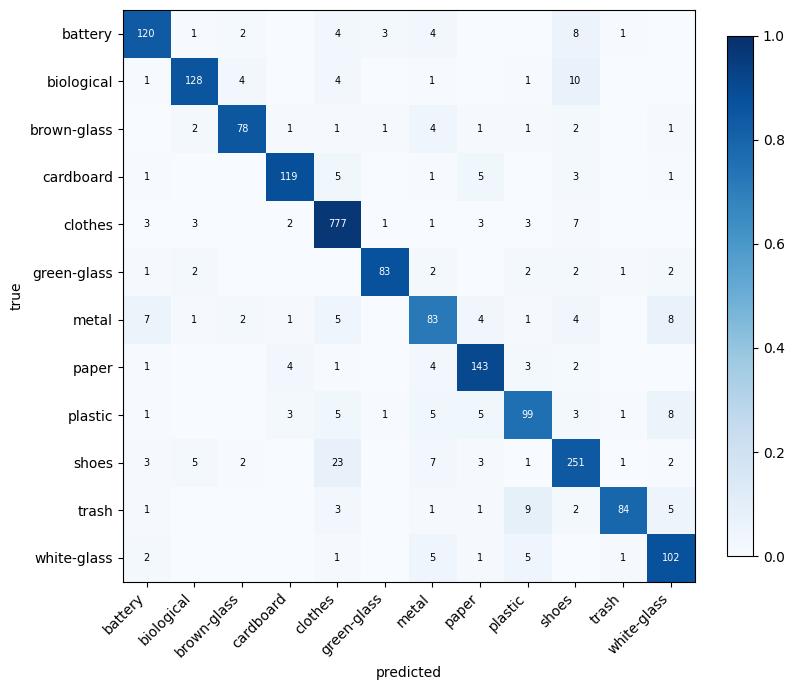

shoes        → clothes       23장 (7.7%)
biological   → shoes         10장 (6.7%)
trash        → plastic        9장 (8.5%)
plastic      → white-glass    8장 (6.1%)
metal        → white-glass    8장 (6.9%)
battery      → shoes          8장 (5.6%)
shoes        → metal          7장 (2.3%)
metal        → battery        7장 (6.0%)
clothes      → shoes          7장 (0.9%)
white-glass  → plastic        5장 (4.3%)
오답: 273 / 2340 | 평균 확신도 정답: 0.959 오답: 0.746


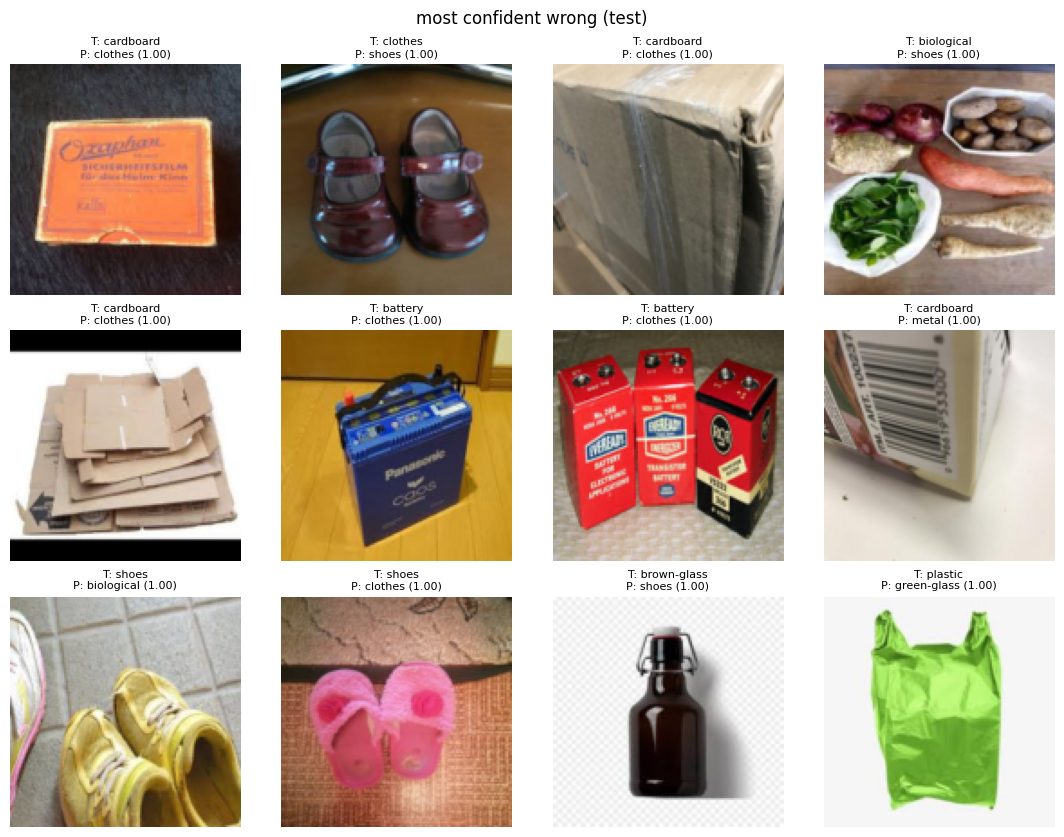

In [ ]:
# 혼동행렬 + 상위 혼동 쌍 + 확신도 (최종 모델)
o = out[fn]; cm = o["cm"]; cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(K)); ax.set_xticklabels(classes, rotation=45, ha="right")
ax.set_yticks(range(K)); ax.set_yticklabels(classes)
for i in range(K):
    for j in range(K):
        if cm[i, j] > 0:
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                    color="white" if cmn[i, j] > 0.5 else "black")
ax.set_xlabel("predicted"); ax.set_ylabel("true"); plt.colorbar(im, fraction=0.04)
plt.tight_layout(); plt.show()

pairs = sorted([(cm[i, j], i, j) for i in range(K) for j in range(K) if i != j and cm[i, j] > 0], reverse=True)
for n, i, j in pairs[:10]:
    print(f"{classes[i]:12s} → {classes[j]:12s} {n:3d}장 ({n / cm[i].sum() * 100:.1f}%)")

P, T, C = o["P"], o["T"], o["C"]
wrong = (P != T).nonzero().flatten()
print("오답:", len(wrong), "/", len(T),
      "| 평균 확신도 정답:", round(C[P == T].mean().item(), 3), "오답:", round(C[wrong].mean().item(), 3))

order = C[wrong].argsort(descending=True)[:12]
fig, axes = plt.subplots(3, 4, figsize=(11, 8.5))
for ax, i in zip(axes.flat, wrong[order].tolist()):
    ax.imshow(X[test_idx[i]].permute(1, 2, 0))
    ax.set_title(f"T: {classes[T[i]]}\nP: {classes[P[i]]} ({C[i]:.2f})", fontsize=8); ax.axis("off")
fig.suptitle("most confident wrong (test)"); plt.tight_layout(); plt.show()

유사도 ≥ 0.999: 18 / 2340
유사도 ≥ 0.99: 25 / 2340
유사도 ≥ 0.98: 31 / 2340
유사도 ≥ 0.95: 99 / 2340


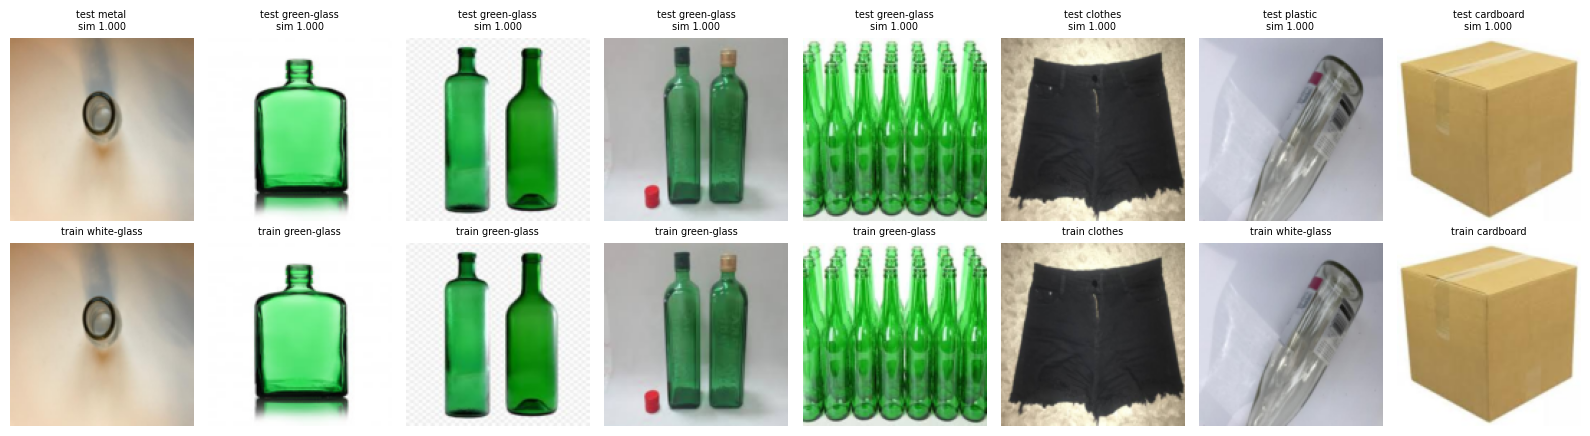

In [ ]:
import torch.nn.functional as F

def thumb(idx, size=16):
    x = X[idx].float().mean(dim=1, keepdim=True) / 255.0        # 흑백
    t = F.adaptive_avg_pool2d(x, size).flatten(1)                # (n, 256)
    t = t - t.mean(1, keepdim=True)
    return t / (t.norm(dim=1, keepdim=True) + 1e-6)

tr, te = thumb(train_idx).to(device), thumb(test_idx).to(device)
best, nn_idx = (te @ tr.T).max(dim=1)                            # 코사인 유사도
best, nn_idx = best.cpu(), nn_idx.cpu()

for th in (0.999, 0.99, 0.98, 0.95):
    print(f"유사도 ≥ {th}: {(best >= th).sum().item()} / {len(best)}")

# 가장 비슷한 쌍 8개: 위 = 시험, 아래 = 가장 닮은 학습 이미지
top = best.argsort(descending=True)[:8]
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for c, i in enumerate(top.tolist()):
    j = nn_idx[i].item()
    axes[0, c].imshow(X[test_idx[i]].permute(1, 2, 0))
    axes[0, c].set_title(f"test {classes[y[test_idx[i]]]}\nsim {best[i]:.3f}", fontsize=7)
    axes[1, c].imshow(X[train_idx[j]].permute(1, 2, 0))
    axes[1, c].set_title(f"train {classes[y[train_idx[j]]]}", fontsize=7)
    axes[0, c].axis("off"); axes[1, c].axis("off")
plt.tight_layout(); plt.show()

In [ ]:
P, T = out[fn]["P"], out[fn]["T"]            # 시험 순서 = test_idx 순서
correct = (P == T)
same_label = (y[train_idx][nn_idx] == T)     # 가장 닮은 학습 이미지의 라벨 == 시험 이미지의 정답?

for th in (0.999, 0.99, 0.98):
    m = best >= th
    print(f"sim ≥ {th}: {m.sum().item():3d}장 | 닮은 학습 이미지와 라벨 일치 {same_label[m].float().mean():.2f} "
          f"| 이 부분 정확도 {correct[m].float().mean():.3f} | 나머지 정확도 {correct[~m].float().mean():.3f}")

# 기준선과 최종 모델을 같은 기준(0.98 이상 제외)으로 비교
m = best >= 0.98
for name, o in out.items():
    c = (o["P"] == o["T"])
    print(f"{name:20s} 전체 {c.float().mean():.4f} | 의심 {m.sum().item()}장 제외 {c[~m].float().mean():.4f}")

sim ≥ 0.999:  18장 | 닮은 학습 이미지와 라벨 일치 0.89 | 이 부분 정확도 0.889 | 나머지 정확도 0.883
sim ≥ 0.99:  25장 | 닮은 학습 이미지와 라벨 일치 0.88 | 이 부분 정확도 0.920 | 나머지 정확도 0.883
sim ≥ 0.98:  31장 | 닮은 학습 이미지와 라벨 일치 0.90 | 이 부분 정확도 0.935 | 나머지 정확도 0.883
base(참고)             전체 0.7803 | 의심 31장 제외 0.7783
final: bn+aug_cos    전체 0.8833 | 의심 31장 제외 0.8826


In [ ]:
!ls -lh /content/*.pt                          # 작업 폴더에 남아 있는지
from google.colab import drive; drive.mount('/content/drive')
!find /content/drive -name "bn+aug_cos_final.pt"    # 드라이브에 저장해 둔 적이 있는지

ls: cannot access '/content/*.pt': No such file or directory
Mounted at /content/drive


In [ ]:
#코랩 세션 초기화돼서 최종 모델만 다시 학습
import os, math, time, random
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import kagglehub
from google.colab import drive, files

drive.mount('/content/drive')
SAVE_DIR = '/content/drive/MyDrive/garbage_model'; os.makedirs(SAVE_DIR, exist_ok=True)

# ---------- 데이터 (노트북 셀 1, 6, 7과 동일) ----------
path = kagglehub.dataset_download("mostafaabla/garbage-classification")
data_dir = os.path.join(path, "garbage_classification")
SEED, IMG = 42, 128
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
classes = sorted(os.listdir(data_dir)); class_to_idx = {c: i for i, c in enumerate(classes)}
paths, labels = [], []
for c in classes:
    for f in sorted(os.listdir(os.path.join(data_dir, c))):
        if f.lower().endswith((".jpg", ".jpeg", ".png")):
            paths.append(os.path.join(data_dir, c, f)); labels.append(class_to_idx[c])
labels = np.array(labels); K = len(classes)

rng = np.random.default_rng(SEED)
train_idx, val_idx, test_idx = [], [], []
for k in range(K):
    idx = np.where(labels == k)[0]; rng.shuffle(idx)
    n_tr, n_va = int(len(idx) * 0.70), int(len(idx) * 0.15)
    train_idx += idx[:n_tr].tolist(); val_idx += idx[n_tr:n_tr + n_va].tolist(); test_idx += idx[n_tr + n_va:].tolist()
print("train/val/test:", len(train_idx), len(val_idx), len(test_idx))   # 10854 2321 2340 이어야 함

def load_img(p):
    with Image.open(p) as im:
        return np.asarray(im.convert("RGB").resize((IMG, IMG), Image.BILINEAR), dtype=np.uint8)
X = torch.from_numpy(np.stack([load_img(p) for p in paths])).permute(0, 3, 1, 2).contiguous()
y = torch.from_numpy(labels).long()
torch.save({"X": X, "y": y, "classes": classes, "train_idx": train_idx, "val_idx": val_idx, "test_idx": test_idx},
           f"{SAVE_DIR}/garbage_128.pt")          # 다음엔 이 파일로 데이터 준비를 건너뛸 수 있음

# ---------- 표준화 통계 (학습 데이터만) ----------
def channel_stats(X, idx, chunk=512):
    s = torch.zeros(3); s2 = torch.zeros(3); n = 0
    for i in range(0, len(idx), chunk):
        b = X[idx[i:i + chunk]].float() / 255.0
        s += b.sum(dim=(0, 2, 3)); s2 += (b ** 2).sum(dim=(0, 2, 3)); n += b.shape[0] * b.shape[2] * b.shape[3]
    mean = s / n; return mean, (s2 / n - mean ** 2).sqrt()
mean, std = channel_stats(X, train_idx)
print("mean:", mean, "std:", std)   # [0.6581, 0.6157, 0.5851] / [0.2765, 0.2878, 0.3016] 와 같아야 함

class GarbageDataset(Dataset):
    def __init__(self, indices):
        self.indices, self.mean, self.std = indices, mean.view(3, 1, 1), std.view(3, 1, 1)
    def __len__(self): return len(self.indices)
    def __getitem__(self, i):
        j = self.indices[i]; return ((X[j].float() / 255.0) - self.mean) / self.std, y[j]
train_set, val_set, test_set = GarbageDataset(train_idx), GarbageDataset(val_idx), GarbageDataset(test_idx)
val_loader  = DataLoader(val_set,  batch_size=64, shuffle=False)
test_loader = DataLoader(test_set, batch_size=64, shuffle=False)

# ---------- 모델·증강 (노트북 셀 18과 동일) ----------
device = "cuda" if torch.cuda.is_available() else "cpu"; print("device:", device)
class CNN(nn.Module):
    def __init__(self, n_classes=12, in_size=128, bn=False, dropout=0.0):
        super().__init__()
        chans, layers = [3, 16, 32, 64, 128], []
        for cin, cout in zip(chans[:-1], chans[1:]):
            layers.append(nn.Conv2d(cin, cout, 3, padding=1))
            if bn: layers.append(nn.BatchNorm2d(cout))
            layers += [nn.ReLU(), nn.MaxPool2d(2)]
        self.features = nn.Sequential(*layers)
        flat = chans[-1] * (in_size // 2 ** 4) ** 2
        head = [nn.Flatten()]
        if dropout: head.append(nn.Dropout(dropout))
        head += [nn.Linear(flat, 128), nn.ReLU()]
        if dropout: head.append(nn.Dropout(dropout))
        head.append(nn.Linear(128, n_classes)); self.classifier = nn.Sequential(*head)
    def forward(self, x): return self.classifier(self.features(x))

def augment(x, max_rot=15, scale=(0.9, 1.1), shift=0.1):
    B, dev = x.size(0), x.device
    ang = (torch.rand(B, device=dev) * 2 - 1) * max_rot * math.pi / 180
    sc = torch.empty(B, device=dev).uniform_(*scale)
    flip = (torch.rand(B, device=dev) < 0.5).float() * 2 - 1
    tx = (torch.rand(B, device=dev) * 2 - 1) * shift * 2; ty = (torch.rand(B, device=dev) * 2 - 1) * shift * 2
    cos, sin = torch.cos(ang) / sc, torch.sin(ang) / sc
    theta = torch.zeros(B, 2, 3, device=dev)
    theta[:, 0, 0], theta[:, 0, 1], theta[:, 0, 2] = cos * flip, -sin, tx
    theta[:, 1, 0], theta[:, 1, 1], theta[:, 1, 2] = sin * flip, cos, ty
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    return F.grid_sample(x, grid, padding_mode="reflection", align_corners=False)

@torch.no_grad()
def evaluate(model, loader):
    model.eval(); cm = torch.zeros(K * K, dtype=torch.long)
    for bx, by in loader:
        cm += torch.bincount(by * K + model(bx.to(device)).argmax(1).cpu(), minlength=K * K)
    cm = cm.view(K, K).float()
    return cm.diag().sum().item() / cm.sum().item(), (cm.diag() / cm.sum(1)).mean().item()

# ---------- 최종 모델 학습: BatchNorm + 증강 + 코사인, 60 epoch (노트북 셀 22와 동일) ----------
EPOCHS, BATCH, LR = 60, 64, 1e-3
torch.manual_seed(SEED); np.random.seed(SEED)
model = CNN(K, bn=True).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
loss_fn = nn.CrossEntropyLoss()
tr_loader = DataLoader(train_set, batch_size=BATCH, shuffle=True, generator=torch.Generator().manual_seed(SEED))

t0 = time.time()
for ep in range(1, EPOCHS + 1):
    model.train()
    for bx, by in tr_loader:
        bx, by = augment(bx.to(device)), by.to(device)
        loss = loss_fn(model(bx), by)
        optimizer.zero_grad(); loss.backward(); optimizer.step()
    scheduler.step()
    if ep % 5 == 0 or ep == 1:
        acc, bal = evaluate(model, val_loader)
        print(f"ep {ep:2d} | val acc {acc:.3f} bal {bal:.3f} | {time.time()-t0:.0f}s")

torch.save(model.state_dict(), "bn+aug_cos_final.pt")
torch.save(model.state_dict(), f"{SAVE_DIR}/bn+aug_cos_final.pt")     # 드라이브에도 보관
print("저장 완료")

va, vb = evaluate(model, val_loader); ta, tb = evaluate(model, test_loader)
print(f"검증 acc {va:.4f} bal {vb:.4f}  (이전: 0.861 / 0.813)")
print(f"시험 acc {ta:.4f} bal {tb:.4f}  (이전: 0.8833 / 0.8463)")
files.download("bn+aug_cos_final.pt")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using Colab cache for faster access to the 'garbage-classification' dataset.
train/val/test: 10854 2321 2340
mean: tensor([0.6581, 0.6157, 0.5851]) std: tensor([0.2765, 0.2878, 0.3016])
device: cuda
ep  1 | val acc 0.618 bal 0.510 | 7s
ep  5 | val acc 0.742 bal 0.656 | 26s
ep 10 | val acc 0.777 bal 0.705 | 50s
ep 15 | val acc 0.795 bal 0.708 | 76s
ep 20 | val acc 0.815 bal 0.744 | 102s
ep 25 | val acc 0.815 bal 0.745 | 127s
ep 30 | val acc 0.835 bal 0.777 | 152s
ep 35 | val acc 0.838 bal 0.784 | 177s
ep 40 | val acc 0.849 bal 0.793 | 203s
ep 45 | val acc 0.853 bal 0.797 | 228s
ep 50 | val acc 0.854 bal 0.798 | 253s
ep 55 | val acc 0.858 bal 0.808 | 278s
ep 60 | val acc 0.860 bal 0.809 | 304s
저장 완료
검증 acc 0.8604 bal 0.8090  (이전: 0.861 / 0.813)
시험 acc 0.8803 bal 0.8410  (이전: 0.8833 / 0.8463)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from garbage_model import GarbageClassifier

clf = GarbageClassifier()                 # 같은 폴더의 bn+aug_cos_final.pt를 자동으로 불러옴
print(clf.predict("다운로드.jpg"))        # 아무 이미지로 시험

{'label': 'green-glass', 'index': 5, 'confidence': 0.9790138602256775, 'top_k': [{'label': 'green-glass', 'index': 5, 'prob': 0.9790138602256775}, {'label': 'plastic', 'index': 8, 'prob': 0.018443476408720016}, {'label': 'white-glass', 'index': 11, 'prob': 0.0013586565619334579}], 'probs': {'battery': 0.0011308637913316488, 'biological': 5.427837550087133e-06, 'brown-glass': 6.207818614711869e-08, 'cardboard': 2.4717135715945915e-07, 'clothes': 5.202701117146269e-11, 'green-glass': 0.9790138602256775, 'metal': 3.1160459911916405e-05, 'paper': 1.2236451141234284e-07, 'plastic': 0.018443476408720016, 'shoes': 5.3971402849128935e-06, 'trash': 1.062143473973265e-05, 'white-glass': 0.0013586565619334579}}


In [ ]:
!rm -f /content/garbage_model.py "/content/garbage_model (1).py"

from google.colab import files
up = files.upload()        # 방금 받은 새 garbage_model.py를 선택
!ls -lh /content/*.py      # 이름이 정확히 garbage_model.py 인지 확인
!grep -n "def load_model\|def get_transform" /content/garbage_model.py

Saving garbage_model.py to garbage_model.py
-rw-r--r-- 1 root root 6.2K Nov 23 06:57 /content/garbage_model.py


In [ ]:
from garbage_model import load_model, get_transform
from PIL import Image

model, tf = load_model(), get_transform()
x = tf(Image.open("올린사진이름.jpg")).unsqueeze(0)   # 올린 사진의 실제 파일명으로
print(model(x).argmax(1))

ImportError: cannot import name 'load_model' from 'garbage_model' (/content/garbage_model.py)

In [ ]:
import sys, os

p = "/content/garbage_model.py"
print("파일 크기:", os.path.getsize(p), "bytes")
src = open(p, encoding="utf-8").read()
print("load_model 있음:", "def load_model" in src, "| get_transform 있음:", "def get_transform" in src)

sys.modules.pop("garbage_model", None)      # 메모리에 남은 옛 버전 제거
import garbage_model
print([n for n in dir(garbage_model) if not n.startswith("_")])

파일 크기: 6325 bytes
load_model 있음: False | get_transform 있음: False
['CLASSES', 'CNN', 'DEFAULT_WEIGHTS', 'GarbageClassifier', 'IMG_SIZE', 'Image', 'MEAN', 'STD', 'argparse', 'io', 'nn', 'np', 'os', 'predict', 'torch']


In [ ]:
%%writefile /content/garbage_model.py
"""쓰레기 이미지 분류 모델 (12 클래스) - 추론용 모듈
가중치: bn+aug_cos_final.pt (이 파일과 같은 폴더)
인터페이스: load_model(), get_transform(), GarbageClassifier
"""
import argparse
import io
import os

import numpy as np
import torch
import torch.nn as nn
from PIL import Image

# 학습 때의 클래스 순서(알파벳 순)와 동일해야 한다.
CLASSES = ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass',
           'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']
IMG_SIZE = 128
MEAN = (0.6581, 0.6157, 0.5851)   # 학습 데이터에서 계산한 채널별 평균 (RGB)
STD = (0.2765, 0.2878, 0.3016)    # 채널별 표준편차

_HERE = os.path.dirname(os.path.abspath(__file__))
DEFAULT_WEIGHTS = os.path.join(_HERE, "bn+aug_cos_final.pt")


class CNN(nn.Module):
    """학습에 사용한 CNN과 동일한 구조 (최종 모델: bn=True, dropout=0)."""

    def __init__(self, n_classes=12, in_size=128, bn=False, dropout=0.0):
        super().__init__()
        chans, layers = [3, 16, 32, 64, 128], []
        for cin, cout in zip(chans[:-1], chans[1:]):
            layers.append(nn.Conv2d(cin, cout, 3, padding=1))
            if bn:
                layers.append(nn.BatchNorm2d(cout))
            layers += [nn.ReLU(), nn.MaxPool2d(2)]
        self.features = nn.Sequential(*layers)
        flat = chans[-1] * (in_size // 2 ** 4) ** 2          # 128*8*8 = 8192
        head = [nn.Flatten()]
        if dropout:
            head.append(nn.Dropout(dropout))
        head += [nn.Linear(flat, 128), nn.ReLU()]
        if dropout:
            head.append(nn.Dropout(dropout))
        head.append(nn.Linear(128, n_classes))                # softmax 없음 (로짓 출력)
        self.classifier = nn.Sequential(*head)

    def forward(self, x):
        return self.classifier(self.features(x))


def _to_pil(image):
    """경로 / bytes / PIL / numpy 를 RGB PIL 이미지로 변환."""
    if isinstance(image, Image.Image):
        img = image
    elif isinstance(image, (str, os.PathLike)):
        img = Image.open(image)
    elif isinstance(image, (bytes, bytearray)):
        img = Image.open(io.BytesIO(image))
    elif isinstance(image, np.ndarray):
        arr = image
        if arr.ndim == 3 and arr.shape[0] == 3 and arr.shape[-1] != 3:   # CHW -> HWC
            arr = arr.transpose(1, 2, 0)
        if arr.dtype != np.uint8:
            arr = (np.clip(arr, 0, 1) * 255).round().astype(np.uint8) if arr.max() <= 1.0 else arr.astype(np.uint8)
        img = Image.fromarray(arr)
    else:
        raise TypeError(f"지원하지 않는 입력 형식: {type(image)}")
    return img.convert("RGB")


class _Transform:
    """입력(PIL 등) -> (3, 128, 128) 표준화 float 텐서. 학습 때 전처리와 동일."""

    def __init__(self):
        self._mean = torch.tensor(MEAN).view(3, 1, 1)
        self._std = torch.tensor(STD).view(3, 1, 1)

    def __call__(self, image):
        img = _to_pil(image).resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
        x = torch.from_numpy(np.asarray(img, dtype=np.uint8).copy()).permute(2, 0, 1).float() / 255.0
        return (x - self._mean) / self._std


def get_transform(*args, **kwargs):
    """평가용 전처리 함수를 돌려준다. (인자는 받지만 무시)"""
    return _Transform()


def _parse_load_args(args, kwargs):
    """load_model에 어떤 순서·이름으로 인자가 와도 (가중치 경로, 장치)를 찾아낸다."""
    weights, device = None, None
    for a in list(args) + list(kwargs.values()):
        if a is None or isinstance(a, (bool, int, float)):
            continue
        s = str(a)
        if s.lower().endswith((".pt", ".pth")) or os.path.isfile(s):
            weights = s
        elif s.split(":")[0] in ("cpu", "cuda", "mps"):
            device = s
    return weights, device


def load_model(*args, **kwargs):
    """학습된 모델을 불러와 eval 모드로 돌려준다.
    load_model()  /  load_model("경로/model.pt")  /  load_model("경로/model.pt", "cuda")  /  load_model(device="cuda")
    """
    weights, device = _parse_load_args(args, kwargs)
    device = torch.device(device or "cpu")
    model = CNN(len(CLASSES), bn=True).to(device)
    state = torch.load(weights or DEFAULT_WEIGHTS, map_location=device)
    if isinstance(state, dict) and "state_dict" in state:
        state = state["state_dict"]
    model.load_state_dict(state)
    model.eval()                                              # BatchNorm 때문에 반드시 eval 모드
    return model


class GarbageClassifier:
    def __init__(self, weights_path=DEFAULT_WEIGHTS, device=None):
        self.device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))
        self.classes = list(CLASSES)
        self.model = load_model(weights_path, str(self.device)).to(self.device)
        self._transform = get_transform()

    def preprocess(self, image):
        return self._transform(image)

    @torch.no_grad()
    def predict_proba(self, images):
        if not isinstance(images, (list, tuple)):
            images = [images]
        batch = torch.stack([self.preprocess(im) for im in images]).to(self.device)
        return torch.softmax(self.model(batch), dim=1).cpu()

    def predict(self, image, top_k=3):
        prob = self.predict_proba(image)[0]
        order = prob.argsort(descending=True)
        top = [{"label": self.classes[i], "index": int(i), "prob": float(prob[i])} for i in order[:top_k]]
        return {
            "label": top[0]["label"], "index": top[0]["index"], "confidence": top[0]["prob"],
            "top_k": top, "probs": {c: float(p) for c, p in zip(self.classes, prob)},
        }

    def predict_batch(self, images):
        return [self.classes[int(i)] for i in self.predict_proba(images).argmax(dim=1)]


_default = None


def predict(image, top_k=3, weights_path=DEFAULT_WEIGHTS):
    global _default
    if _default is None:
        _default = GarbageClassifier(weights_path)
    return _default.predict(image, top_k=top_k)


if __name__ == "__main__":
    ap = argparse.ArgumentParser(description="쓰레기 이미지 분류")
    ap.add_argument("images", nargs="+")
    ap.add_argument("--weights", default=DEFAULT_WEIGHTS)
    ap.add_argument("--top-k", type=int, default=3)
    args = ap.parse_args()
    clf = GarbageClassifier(args.weights)
    for path in args.images:
        r = clf.predict(path, top_k=args.top_k)
        print(f"{path}: {r['label']} ({r['confidence']*100:.1f}%)")
        for t in r["top_k"]:
            print(f"   {t['label']:12s} {t['prob']*100:5.1f}%")

Overwriting /content/garbage_model.py


In [ ]:
import sys, os
sys.modules.pop("garbage_model", None)          # 메모리에 남은 옛 버전 제거
print("garbage_model.py 크기:", os.path.getsize("/content/garbage_model.py"), "bytes")
print("가중치 파일 있음:", os.path.exists("/content/bn+aug_cos_final.pt"))

from garbage_model import load_model, get_transform
from PIL import Image

model, tf = load_model(), get_transform()
x = tf(Image.open("다운로드.jpg")).unsqueeze(0)     # 올린 사진의 실제 파일명으로
print(model(x).argmax(1))                              # 클래스 번호 (0~11)

garbage_model.py 크기: 6637 bytes
가중치 파일 있음: True
tensor([5])


In [ ]:
from google.colab import files
files.download("/content/garbage_model.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!ls -lh /content/*.pt

-rw-r--r-- 1 root root 4.4M Nov 23 06:46 /content/bn+aug_cos_final.pt


In [ ]:
from google.colab import files
files.download("/content/bn+aug_cos_final.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>